In [3]:
# Import
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

plt.style.use('ggplot')
%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12, 8)

In [4]:
# Read
folder = r'D:\DownloadV2\Resume\Project\Stock Correlation\data'
df = pd.read_csv(folder + r'\sp500_screener.csv')
df

,No.,Ticker,Company,Sector,Industry,Country,Market Cap ($B),P/E,Price,Change %,...,Dividend %,ROA %,ROE %,Curr R,Quick R,Debt/Eq,Gross M %,Oper M %,Profit M %,Earnings
0,1,NVDA,Nvidia,Information Technology,Semiconductors,United States,5734.19,30.02,237.47,-0.74,...,0.12,53.57,117.21,4.59,2.92,0.17,74.67,66.24,63.66,2026-11-18
1,2,AAPL,Apple Inc.,Information Technology,"Technology Hardware, Storage & Peripherals",United States,4913.42,38.26,336.67,0.91,...,0.31,27.08,148.75,1.00,0.81,0.78,48.65,32.62,27.62,2026-11-03
2,3,GOOGL,Alphabet Inc. (Class A),Communication Services,Interactive Media & Services,United States,4286.59,17.45,350.50,0.81,...,0.24,12.96,48.68,2.72,2.47,0.19,60.90,34.03,54.77,2026-10-29
3,4,GOOG,Alphabet Inc. (Class C),Communication Services,Interactive Media & Services,United States,4248.31,17.29,347.37,0.81,...,0.25,12.96,48.68,2.72,2.47,0.19,60.90,34.03,54.77,2026-10-29
4,5,MSFT,Microsoft,Information Technology,Systems Software,United States,3933.76,29.51,529.76,0.09,...,0.69,14.09,34.04,1.23,1.10,0.29,67.94,45.11,40.30,2026-10-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
498,499,WYNN,Wynn Resorts,Consumer Discretionary,Casinos & Gaming,United States,7.72,18.38,74.97,-2.15,...,1.31,5.73,NaN,0.91,0.84,NaN,68.30,16.54,6.05,2026-11-06
499,500,MGM,MGM Resorts,Consumer Discretionary,Casinos & Gaming,United States,7.68,18.52,30.00,-1.77,...,0.00,1.77,18.92,1.34,1.21,8.93,44.16,6.79,2.40,2026-10-29
500,501,AOS,A. O. Smith,Industrials,Building Products,United States,7.52,15.42,55.34,-2.74,...,2.50,12.54,27.13,1.59,0.98,0.37,38.59,18.93,13.15,2026-10-29
501,502,NCLH,Norwegian Cruise Line Holdings,Consumer Discretionary,"Hotels, Resorts & Cruise Lines",United States,6.91,9.59,15.05,-2.97,...,0.00,4.25,36.73,0.20,0.08,6.21,42.46,14.04,7.49,2026-11-04


In [5]:
# Check missing data
for col in df.columns:
    pct_missing = np.mean(df[col].isnull())
    print('{} - {}%'.format(col, round(pct_missing * 100)))

No. - 0%
Ticker - 0%
Company - 0%
Sector - 0%
Industry - 0%
Country - 0%
Market Cap ($B) - 0%
P/E - 5%
Price - 0%
Change % - 0%
Volume - 0%
Forward P/E - 0%
PEG - 1%
P/S - 0%
P/B - 0%
P/C - 0%
P/FCF - 6%
EPS This Y % - 2%
EPS Next Y % - 1%
Dividend % - 0%
ROA % - 1%
ROE % - 6%
Curr R - 4%
Quick R - 4%
Debt/Eq - 11%
Gross M % - 0%
Oper M % - 0%
Profit M % - 0%
Earnings - 0%


In [6]:
print(df.dtypes)

No.                  int64
Ticker                 str
Company                str
Sector                 str
Industry               str
Country                str
Market Cap ($B)    float64
P/E                float64
Price              float64
Change %           float64
Volume               int64
Forward P/E        float64
PEG                float64
P/S                float64
P/B                float64
P/C                float64
P/FCF              float64
EPS This Y %       float64
EPS Next Y %       float64
Dividend %         float64
ROA %              float64
ROE %              float64
Curr R             float64
Quick R            float64
Debt/Eq            float64
Gross M %          float64
Oper M %           float64
Profit M %         float64
Earnings               str
dtype: object


In [7]:
# Remove duplicate share classes example(GOOGL and GOOG )
duplicate_classes = ['GOOG', 'FOX', 'NWS']
df = df[~df['Ticker'].isin(duplicate_classes)]
df = df.drop_duplicates()
len(df)

500

<Axes: >

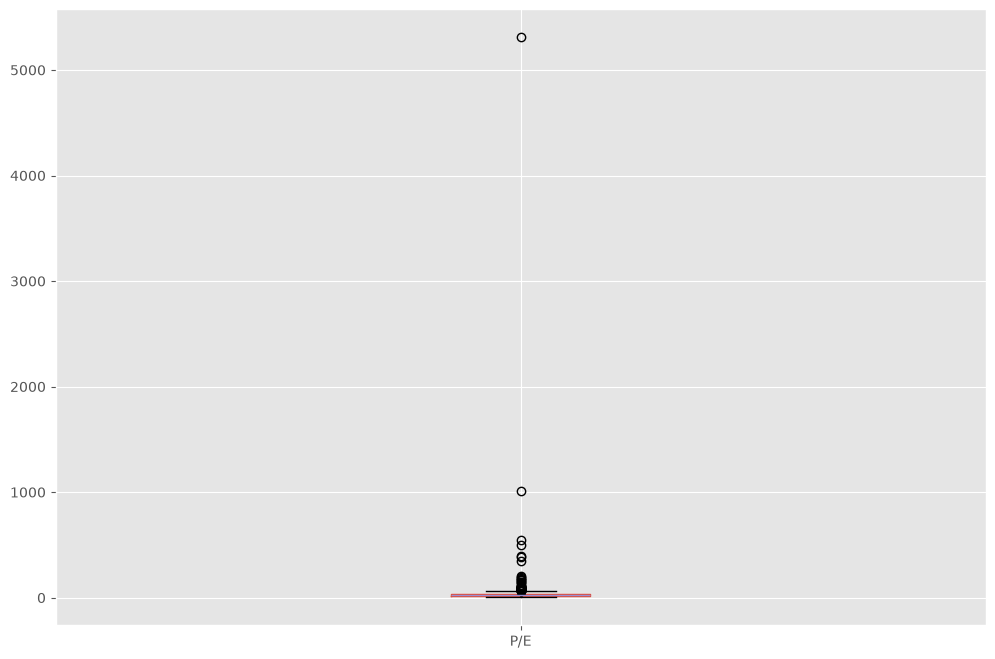

In [8]:
# Check P/E Outliner 
df.boxplot(column=['P/E'])

<Axes: xlabel='ROE %', ylabel='P/B'>

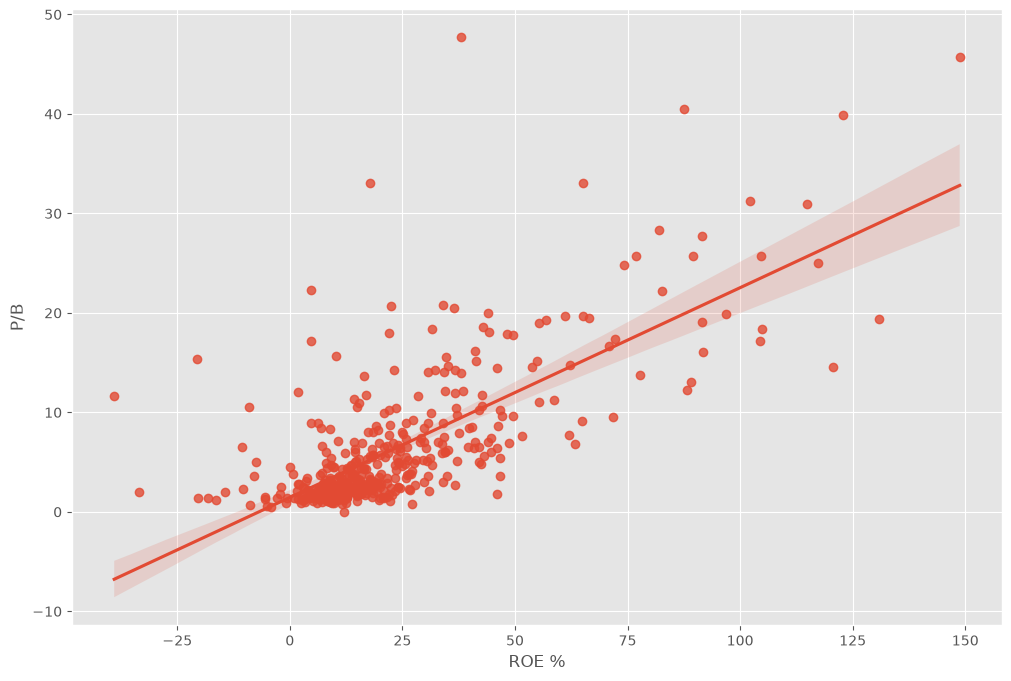

In [9]:
# Filter extreme values so the chart is readable
df_plot = df[(df['P/B'].between(0, 50)) & (df['ROE %'].between(-50, 150))]
sns.regplot(x='ROE %', y='P/B', data=df_plot)

<Axes: xlabel='Profit M %', ylabel='P/S'>

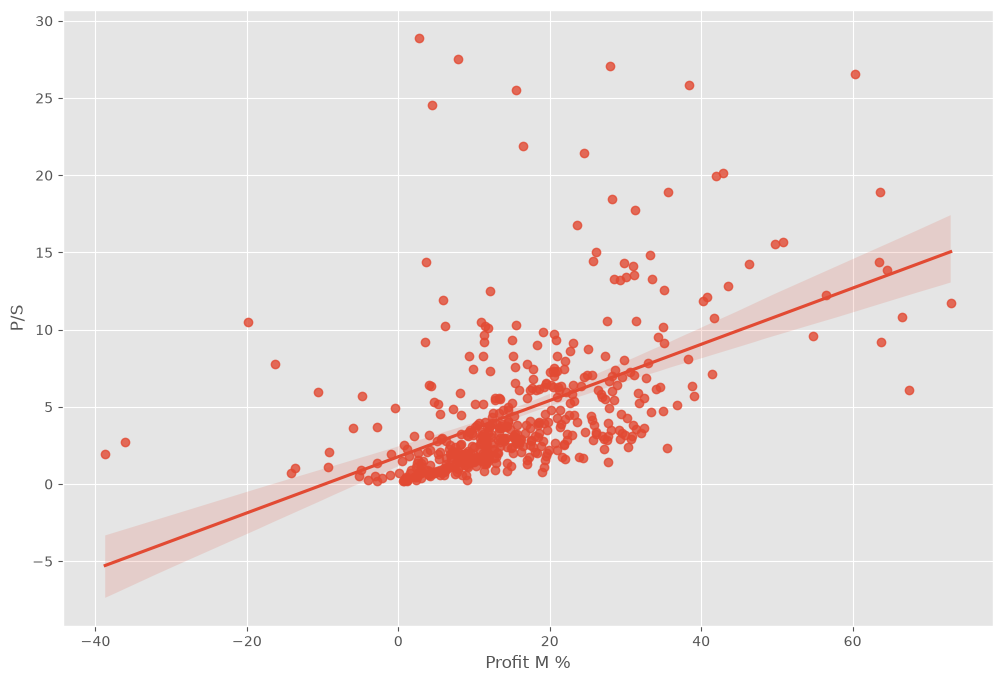

In [10]:
df_plot = df[(df['P/S'] < 30) & (df['Profit M %'].between(-50, 80))]
sns.regplot(x='Profit M %', y='P/S', data=df_plot)

In [11]:
# Correlation - Pearson
numeric_df = df.select_dtypes(include='number').drop(columns=['No.'])
numeric_df.corr(method='pearson')

,Market Cap ($B),P/E,Price,Change %,Volume,Forward P/E,PEG,P/S,P/B,P/C,...,EPS Next Y %,Dividend %,ROA %,ROE %,Curr R,Quick R,Debt/Eq,Gross M %,Oper M %,Profit M %
Market Cap ($B),1.000000,0.023165,0.094831,0.117053,0.486966,0.116717,-0.015635,0.220689,-0.002665,-0.029935,...,0.011079,-0.137629,0.313356,0.012783,0.072514,0.101516,-0.019952,0.103387,0.101010,0.200498
P/E,0.023165,1.000000,0.012127,-0.152182,0.023775,0.516477,0.023128,0.430875,0.013989,-0.009873,...,0.064395,-0.087462,-0.078770,-0.014141,0.019538,0.040684,-0.010394,0.076548,-0.116164,-0.099999
Price,0.094831,0.012127,1.000000,-0.072285,-0.131093,0.087951,-0.036659,0.144826,0.117466,-0.006081,...,-0.007400,-0.281117,0.273321,-0.004478,0.133435,0.073951,0.025313,0.011194,0.047697,0.028972
Change %,0.117053,-0.152182,-0.072285,1.000000,0.150424,-0.182791,-0.007499,-0.016329,0.002043,-0.029257,...,0.049173,0.047304,0.122297,-0.009850,-0.038171,0.028985,0.001947,0.094202,-0.075673,0.035670
Volume,0.486966,0.023775,-0.131093,0.150424,1.000000,0.033400,0.085910,0.123966,-0.034064,-0.063111,...,0.022918,0.064997,0.095156,-0.015862,0.076270,0.076819,-0.029555,-0.003838,-0.014806,0.024739
Forward P/E,0.116717,0.516477,0.087951,-0.182791,0.033400,1.000000,0.038828,0.498936,0.055782,0.091603,...,0.068589,-0.165934,-0.025138,-0.017771,0.035595,0.083884,-0.026614,0.174162,0.106538,0.067678
PEG,-0.015635,0.023128,-0.036659,-0.007499,0.085910,0.038828,1.000000,0.007320,-0.008007,0.008226,...,-0.019376,0.157911,-0.059755,-0.015020,-0.044881,-0.044655,-0.014035,0.049187,0.021759,0.018240
P/S,0.220689,0.430875,0.144826,-0.016329,0.123966,0.498936,0.007320,1.000000,0.039868,-0.001172,...,0.044956,-0.262220,0.219379,-0.018363,0.258549,0.364383,-0.022471,0.366583,-0.003783,0.096278
P/B,-0.002665,0.013989,0.117466,0.002043,-0.034064,0.055782,-0.008007,0.039868,1.000000,0.043474,...,0.034505,-0.087517,0.095480,0.057477,-0.021250,-0.014178,0.791098,0.055465,0.013749,0.019877
P/C,-0.029935,-0.009873,-0.006081,-0.029257,-0.063111,0.091603,0.008226,-0.001172,0.043474,1.000000,...,-0.013176,0.076824,-0.023093,-0.013699,-0.109717,-0.100855,0.007230,0.008543,-0.001204,0.026592


In [12]:
# Correlation - spearman
numeric_df.corr(method='spearman')

,Market Cap ($B),P/E,Price,Change %,Volume,Forward P/E,PEG,P/S,P/B,P/C,...,EPS Next Y %,Dividend %,ROA %,ROE %,Curr R,Quick R,Debt/Eq,Gross M %,Oper M %,Profit M %
Market Cap ($B),1.000000,0.229090,0.425928,0.126557,0.323106,0.288728,0.029318,0.405635,0.351361,0.046304,...,0.153139,-0.137266,0.149534,0.236408,0.018102,0.102203,-0.046243,0.128584,0.231386,0.262639
P/E,0.229090,1.000000,0.299618,-0.116313,-0.073824,0.708025,0.069997,0.530202,0.407202,0.308053,...,0.427256,-0.339133,0.043858,-0.194967,0.212033,0.224713,-0.134102,0.201804,-0.099114,-0.167150
Price,0.425928,0.299618,1.000000,-0.033734,-0.540431,0.380360,0.003168,0.389383,0.440281,0.213592,...,0.202384,-0.435930,0.350000,0.357644,0.159823,0.217116,-0.174454,0.084273,0.118880,0.207462
Change %,0.126557,-0.116313,-0.033734,1.000000,0.156431,-0.105705,0.042238,-0.021477,-0.039688,-0.021468,...,-0.153103,0.054596,0.121708,0.086169,-0.133541,-0.094638,0.024252,0.137759,0.115020,0.071244
Volume,0.323106,-0.073824,-0.540431,0.156431,1.000000,-0.146370,-0.096936,0.000112,-0.058015,-0.149915,...,0.045396,0.154265,-0.127860,-0.098273,-0.011190,-0.012241,0.072138,0.034354,0.018668,-0.001162
Forward P/E,0.288728,0.708025,0.380360,-0.105705,-0.146370,1.000000,0.348683,0.635185,0.458942,0.420017,...,0.224867,-0.272711,0.144389,0.073243,0.056273,0.122406,-0.088371,0.255681,0.068227,0.158110
PEG,0.029318,0.069997,0.003168,0.042238,-0.096936,0.348683,1.000000,0.181584,0.062405,0.246382,...,-0.261217,0.214378,0.038408,-0.027758,-0.130849,-0.122609,0.025634,0.100004,0.090636,0.111488
P/S,0.405635,0.530202,0.389383,-0.021477,0.000112,0.635185,0.181584,1.000000,0.440598,0.339231,...,0.276341,-0.284778,0.226077,0.108732,0.150678,0.259347,-0.235095,0.611176,0.599196,0.629527
P/B,0.351361,0.407202,0.440281,-0.039688,-0.058015,0.458942,0.062405,0.440598,1.000000,0.213583,...,0.290341,-0.362985,0.427471,0.636632,0.196390,0.237833,0.136947,0.212899,0.031033,0.146252
P/C,0.046304,0.308053,0.213592,-0.021468,-0.149915,0.420017,0.246382,0.339231,0.213583,1.000000,...,-0.033504,0.020107,0.265535,0.082860,-0.262082,-0.332160,0.084127,0.203349,0.143020,0.135130


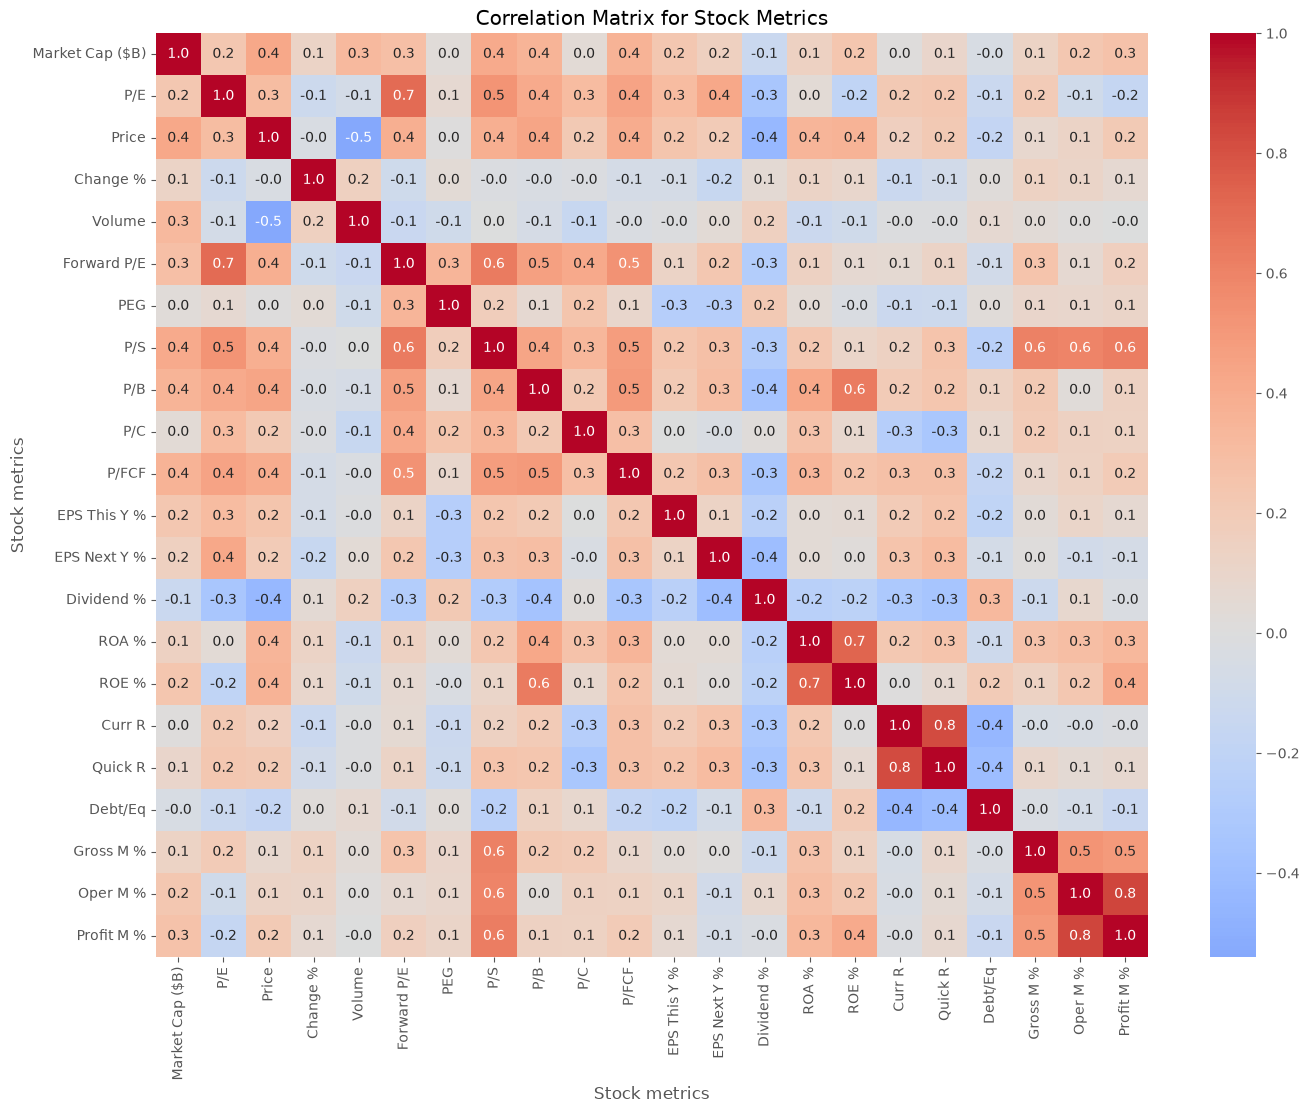

In [13]:
# Heatmap - Finding Relations 
correlation_matrix = numeric_df.corr(method='spearman')

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix for Stock Metrics')
plt.xlabel('Stock metrics')
plt.ylabel('Stock metrics')
plt.show()

In [14]:
#Strong pairs (|correlation| > 0.5)
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1))
sorted_pairs = upper.stack().dropna().sort_values()

strong_pairs = sorted_pairs[abs(sorted_pairs) > 0.5]
print(strong_pairs)

Price        Volume        -0.540431
P/E          P/S            0.530202
Gross M %    Oper M %       0.530206
Forward P/E  P/FCF          0.536476
P/S          Oper M %       0.599196
             Gross M %      0.611176
             Profit M %     0.629527
Forward P/E  P/S            0.635185
P/B          ROE %          0.636632
P/E          Forward P/E    0.708025
ROA %        ROE %          0.725869
Curr R       Quick R        0.825063
Oper M %     Profit M %     0.844807
dtype: float64


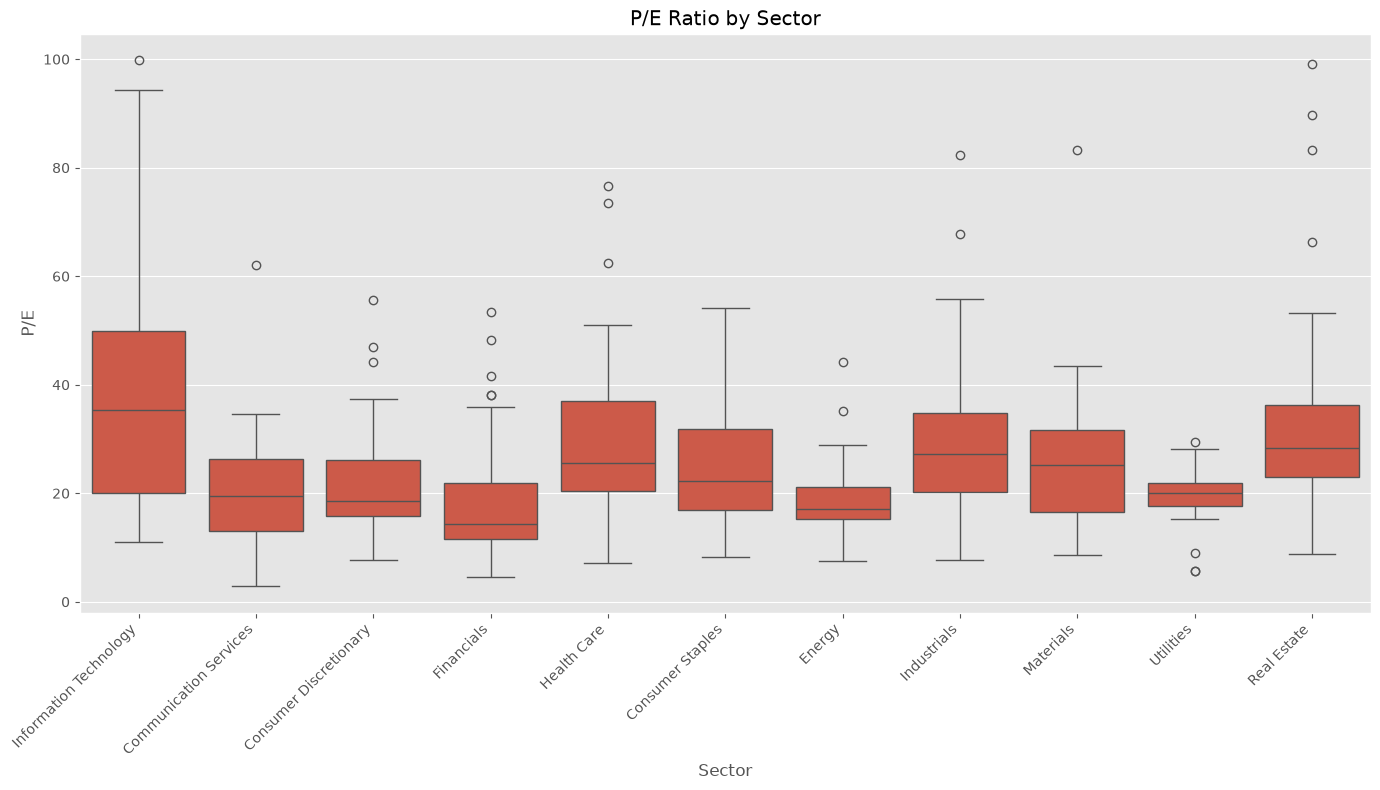

In [16]:
# P/E by Sector - Box Plot
plt.figure(figsize=(14, 8))
sns.boxplot(x='Sector', y='P/E', data=df[df['P/E'] < 100])
plt.xticks(rotation=45, ha='right')
plt.title('P/E Ratio by Sector')
plt.tight_layout()
plt.show()

In [17]:
df.groupby('Sector')[['P/E', 'ROE %', 'Profit M %', 'Dividend %']].median().round(2)

,P/E,ROE %,Profit M %,Dividend %
Sector,,,,
Communication Services,21.42,15.84,9.05,0.70
Consumer Discretionary,18.71,37.14,11.43,1.04
Consumer Staples,22.48,19.84,7.57,2.91
Energy,17.13,14.92,13.54,2.27
Financials,14.46,16.16,22.30,1.65
Health Care,27.32,14.04,9.90,0.52
Industrials,27.36,24.40,12.38,1.15
Information Technology,37.36,23.23,19.14,0.10
Materials,28.79,14.66,7.72,1.77
